# Nastoyka · авторское меню Санкт-Петербурга

**10 вкусов · порция 50 мл · пятница и суббота**

От публичных отзывов и меню конкурентов — к авторскому выбору десяти настоек и закупке для двух вечеров. Здесь собраны готовое меню, результаты исследования и экономика сырья. Подробная модель остаётся в [техническом Notebook](assortment_economics.ipynb).

Цены продажи, состав и выпуск согласованы автором. Выходы оценочные, закупочные цены сценарные, фактических продаж нет. Презентация и таблица закупки не содержат дозировок отдельных напитков и полных рецептур.

Сохранённые карточки, таблицы и графики видны на GitHub без запуска. **Run All Cells** в Jupyter пересчитывает модель и обновляет данные презентации.

In [1]:
from pathlib import Path
from datetime import date
from IPython.display import display, Image, Markdown
from scripts import economics as e
from scripts.report import fmt, table, menu_card_image

result = e.run()
menu = e.read_csv(e.DATA / "author_selected_menu.csv")
costs = e.read_csv(e.OUT / "recipe_costs.csv")
purchases = e.read_csv(e.DATA / "menu_raw_material_costs.csv")
suppliers = e.read_csv(e.OUT / "suppliers.csv")
research = e.read_json(e.ROOT / "data/processed/summary.json")
def show(headers, rows): display(Markdown(table(headers, rows)))
def figure(name): display(Image(filename=str(e.FIG / name)))
assert len(menu) == 10 and len(purchases) == 16
print("Ценовой сценарий:", date.fromisoformat(result["scenario_date"]).strftime("%d.%m.%Y"))

Ценовой сценарий: 16.10.2026


## 01 · От отзывов к авторскому решению

Изучались бары, рюмочные и рестораны Санкт-Петербурга: ассортимент конкурентов и конкретные впечатления гостей. Разные названия одного вкуса нормализовали, сохраняя исходный вариант; разные сочетания ингредиентов не объединяли. Одному отзыву могут соответствовать несколько упоминаний.

In [2]:
show(["Исследование", "База наблюдений"], [
    ["Заведения актуального среза", research["current_sample"]],
    ["Собрано / проверено публикаций", str(research["reviews_total"])+" / "+str(research["reviews_verified_unique"])],
    ["Конкретные подтверждённые упоминания", research["concrete_mentions_verified"]],
    ["Отзывы с конкретными упоминаниями", research["reviews_with_concrete_flavors"]],
    ["Нормализованные вкусы", research["normalized_flavors_verified"]],
    ["Строгий срез: упоминания / отзывы", str(research["conservative_concrete_mentions"])+" / "+str(research["conservative_reviews_with_concrete_flavors"])],
])
flavors = e.read_csv(e.ROOT / "data/processed/flavor_summary.csv")
show(["Вкус", "Проверенные упоминания", "Положительные", "Заведения"], [
    [row["Вкус"], row["Проверенные упоминания"], row["Положительные"], row["Заведения"]]
    for row in flavors if row["Вкус"] in {"Хреновуха", "Щавель"}
])

| Исследование | База наблюдений |
| --- | --- |
| Заведения актуального среза | 30 |
| Собрано / проверено публикаций | 368 / 358 |
| Конкретные подтверждённые упоминания | 198 |
| Отзывы с конкретными упоминаниями | 108 |
| Нормализованные вкусы | 114 |
| Строгий срез: упоминания / отзывы | 143 / 84 |

| Вкус | Проверенные упоминания | Положительные | Заведения |
| --- | --- | --- | --- |
| Хреновуха | 7 | 5 | 6 |
| Щавель | 7 | 5 | 3 |

Хреновуха и щавель — заметные сигналы в небольшой выборке. Они не доказывают спрос всего города. Отзывы не равны продажам и не представляют всех посетителей; часть публикаций доступна лишь фрагментами.

Исследование помогло сформировать варианты меню. **Финальные десять вкусов и разделение 8+2 выбрал автор**, а не алгоритм оптимизации. Клюква сохранена автором, несмотря на отсутствие подтверждённых положительных оценок в текущем наборе.

[Excel исследования](data/nastoyki_reviews.xlsx) · [Методика](docs/methodology.md) · [Результаты сбора](docs/collection_report.md)

## 02 · Меню для гостей

Восемь основных — **250 ₽**, два премиальных — **300 ₽** за 50 мл. Описания основаны на ингредиентах, а не на новом дегустационном тесте.

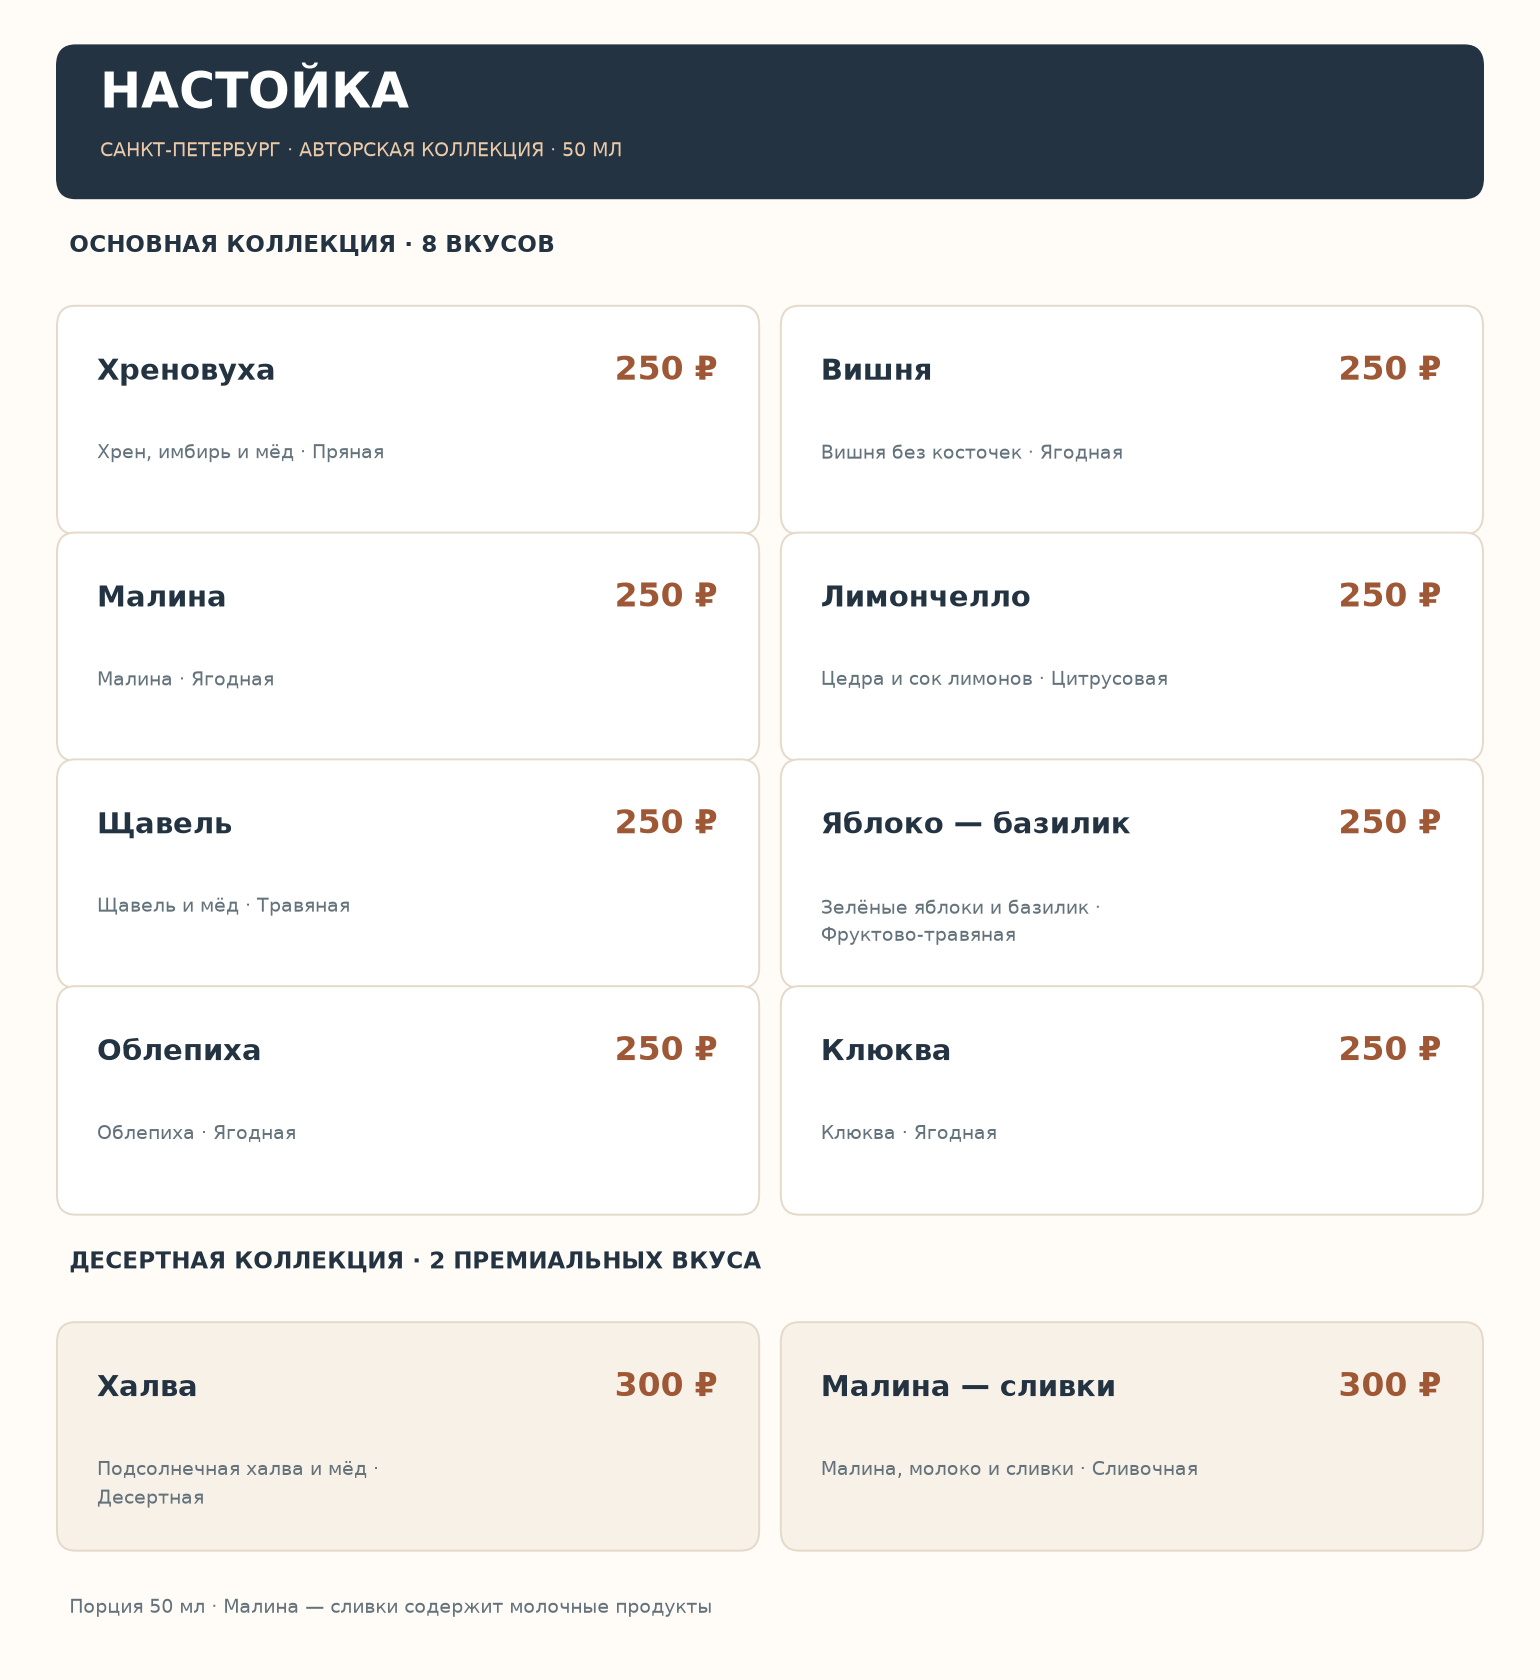

In [3]:
display(Image(data=menu_card_image(menu), format="png"))

## 03 · План на два вечера

По **6 л каждого вкуса**: 120 порций, по 60 на пятницу и субботу. Конкретная дата запуска не назначена. Равный выпуск не означает равный спрос.

In [4]:
show(["Производственный план", "Объём"], [
    ["Готовые напитки", fmt(result["total_ready_ml"]/1000,0)+" л"],
    ["Порции по 50 мл", fmt(result["total_portions"],0)],
])
show(["Финансовый показатель", "Сценарий, ₽"], [
    [label,fmt(result[key])] for label,key in [
        ("Первоначальная закупка сырья","purchase_cost_rub"),
        ("Израсходованное сырьё","used_cost_rub"),
        ("Остаток закупленного сырья","leftover_value_rub"),
        ("Выручка при продаже всех порций","potential_revenue_rub"),
        ("Доход после израсходованного сырья","potential_material_contribution_rub"),
    ]
])
print("Средний расход сырья на 50 мл:", fmt(e.times(result["used_cost_rub"],1/result["total_portions"])), "₽")

| Производственный план | Объём |
| --- | --- |
| Готовые напитки | 60 л |
| Порции по 50 мл | 1 200 |

| Финансовый показатель | Сценарий, ₽ |
| --- | --- |
| Первоначальная закупка сырья | 40 002,80 |
| Израсходованное сырьё | 36 357,61 |
| Остаток закупленного сырья | 3 645,19 |
| Выручка при продаже всех порций | 312 000,00 |
| Доход после израсходованного сырья | 275 642,39 |

Средний расход сырья на 50 мл: 30,30 ₽


Потенциальная выручка относится к полной продаже, это не полученные деньги. Материальный доход не является чистой прибылью. Закупка — платёж за упаковки; производственный расход — использованное сырьё; остатки — запас, пригодность которого зависит от хранения.

## 04 · Себестоимость десяти вкусов

Сырьевые затраты рассчитаны на 6 л каждого вкуса, без промежуточного округления. Цены продажи остаются авторскими: себестоимость сама по себе не доказывает готовность гостя платить.

| Настойка | Цена 50 мл, ₽ | Сырьё 50 мл, ₽ | Сырьё 6 л, ₽ |
| --- | --- | --- | --- |
| Хреновуха | 250,00 | 27,69 | 3 322,66 |
| Вишня | 250,00 | 29,56 | 3 547,61 |
| Малина | 250,00 | 37,08 | 4 449,53 |
| Лимончелло | 250,00 | 25,22 | 3 026,20 |
| Щавель | 250,00 | 34,14 | 4 096,98 |
| Яблоко — базилик | 250,00 | 21,29 | 2 554,68 |
| Облепиха | 250,00 | 27,55 | 3 306,58 |
| Клюква | 250,00 | 30,49 | 3 658,52 |
| Халва | 300,00 | 36,91 | 4 428,93 |
| Малина — сливки | 300,00 | 33,05 | 3 965,91 |

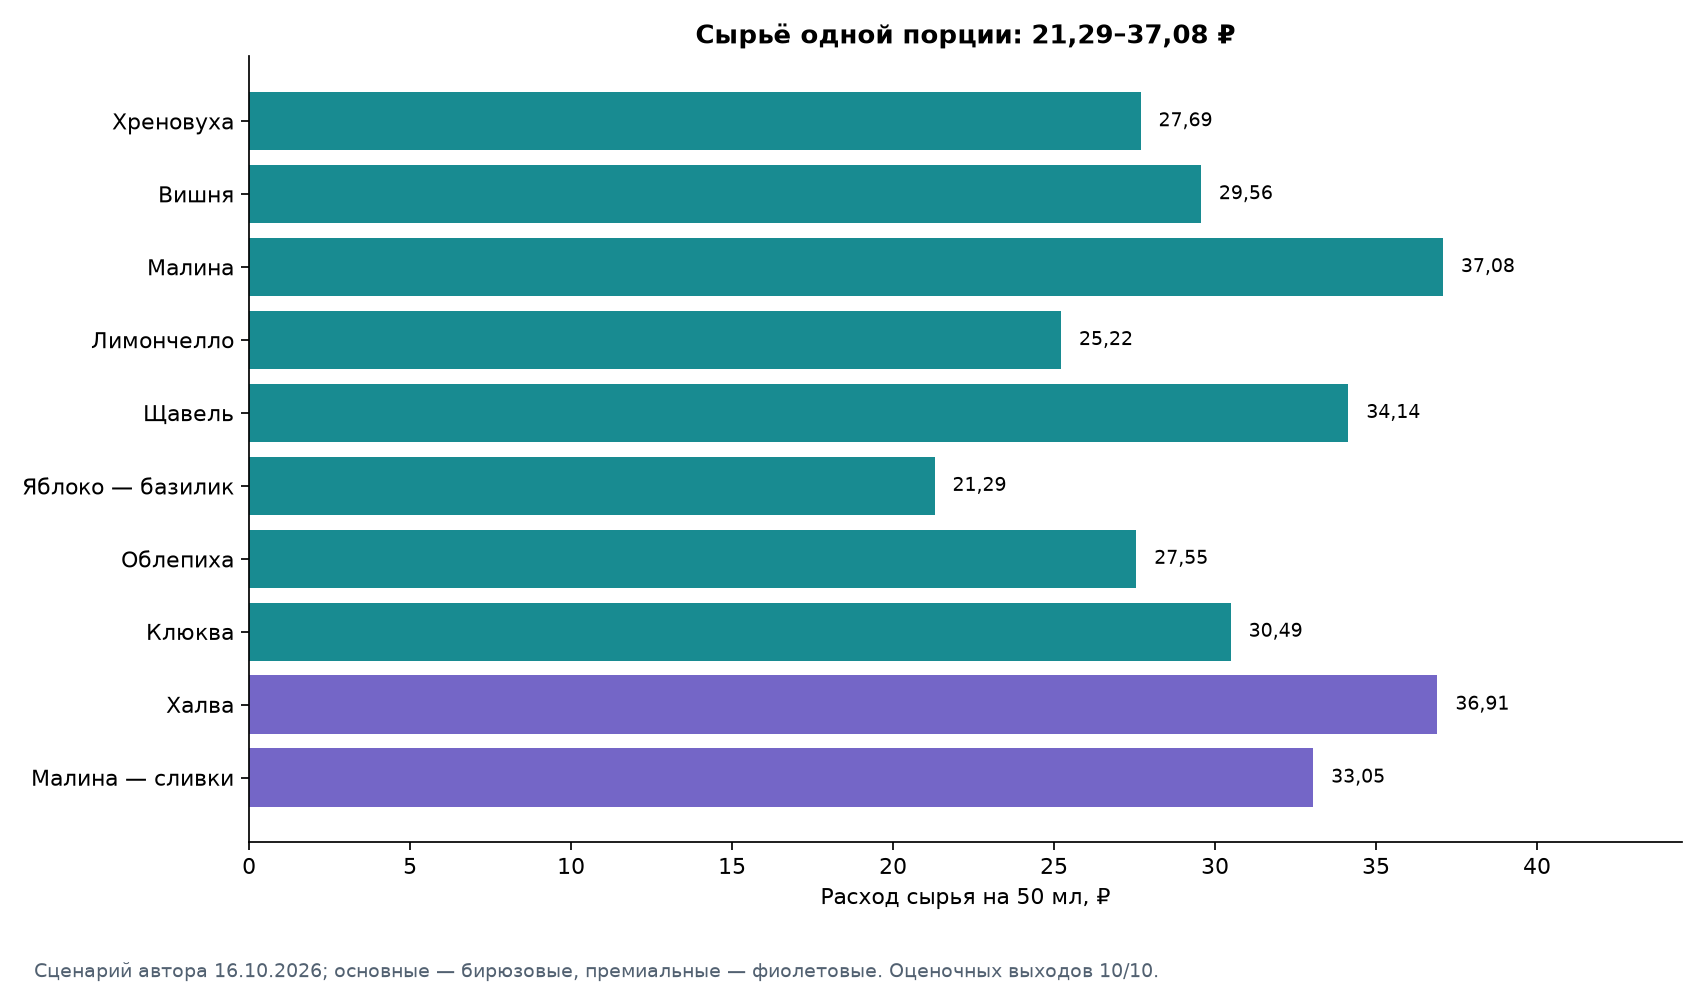

In [5]:
show(["Настойка", "Цена 50 мл, ₽", "Сырьё 50 мл, ₽", "Сырьё 6 л, ₽"], [
    [row["normalized_flavor"],fmt(row["price_50ml_rub"]),fmt(row["cost_50ml_rub"] or None),fmt(row["used_cost_rub"] or None)]
    for row in costs
])
figure("cost_50ml.png")

## 05 · Общая закупка сырья

Одинаковые продукты сначала суммируются по всему меню, затем закупка округляется до упаковок. **[Таблица расходов на сырьё](data/economics/menu_raw_material_costs.csv)** обновляется автоматически вместе с моделью: 16 ингредиентов, поставщики, общие количества, фасовки, цены, расходы и остатки. В таблице нет привязки дозировок к отдельным настойкам.

Презентационный CSV округляет количества и деньги только для отображения. Итоги ниже получены из расчёта до округления строк.

| Поставщик | Первая закупка, ₽ |
| --- | --- |
| Ладога | 18 240,00 |
| METRO | 19 781,80 |
| Агропарк СПб | 1 981,00 |
| ВСЕГО | 40 002,80 |

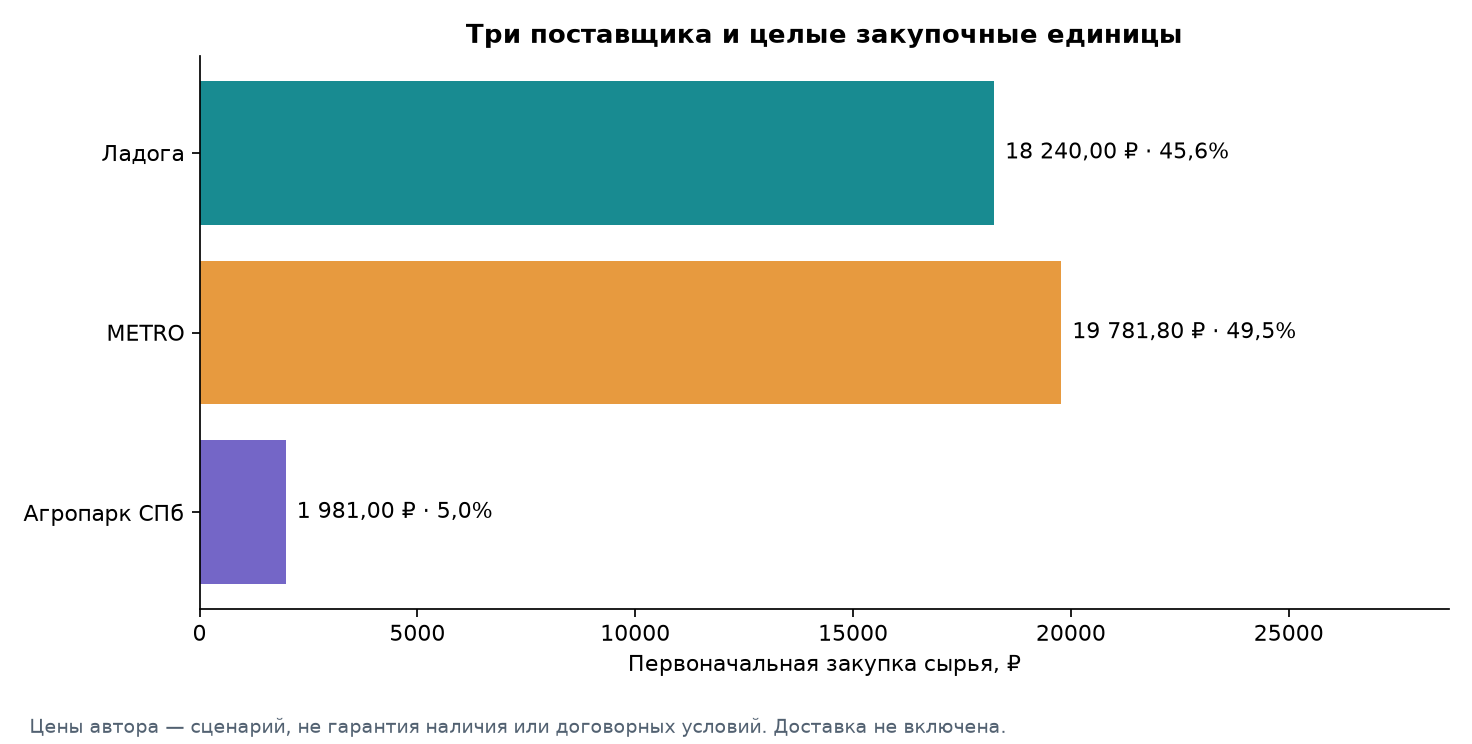

Сводка закупки: 16 ингредиентов; дозировки отдельных напитков не экспортируются.


In [6]:
show(["Поставщик", "Первая закупка, ₽"], [
    [row["supplier"],fmt(row["purchase_cost_rub"] or None)] for row in suppliers
]+[["ВСЕГО",fmt(result["purchase_cost_rub"])]])
figure("supplier_budget.png")
assert result["total_ready_ml"] == 60000 and result["total_portions"] == 1200
assert not result["optimizer_called"]
print("Сводка закупки:", len(purchases), "ингредиентов; дозировки отдельных напитков не экспортируются.")

## 06 · Готовый результат

Авторское меню из десяти настоек связано с исследованием рынка и общей закупкой для **60 л / 1 200 порций**. Итоги базового ценового сценария показаны выше и обновляются из действующей модели. Это согласованный сценарий, а не фактические продажи.

Модель сохраняет ограничения: выходы оценочные; при неприменимом ценовом пороге без обычной цены финансовый итог недоступен. Цены и условия закупки нужно подтвердить перед заказом. Для малины — сливок безопасный срок хранения не установлен в рамках проекта.

Для просмотра достаточно этого Notebook и [общей таблицы сырья](data/economics/menu_raw_material_costs.csv). [Технический Notebook](assortment_economics.ipynb) и [подробный отчёт](docs/economics_report.md) сохранены отдельно.